# TP Parte 1: Algoritmos Genéticos
**Inteligencia Artificial, Lic. en Sistemas de Información (UADER, FCyT Oro Verde), 2026**

In [1]:
import random
import statistics
import string
import time

import matplotlib.pyplot as plt
import numpy as np

---
## Actividad 1: Búsqueda de la cadena de texto

**Enunciado:** encontrar con un AG el texto `"Los algoritmos genéticos sirven para optimizar"` y determinar automáticamente qué tamaño de población de `PS = [100, 1000, 50, 200, 300, 50, 500]` se ajusta mejor al problema.

### Planteo

| Elemento | Decisión |
|---|---|
| **Individuo** | Cadena de 46 caracteres (el largo del objetivo). Cada carácter es un gen. |
| **Alfabeto** | `a–z`, `A–Z`, espacio y `á é í ó ú ñ` (59 símbolos). |
| **Función de aptitud** | Cantidad de caracteres que coinciden **en la misma posición** con el objetivo. Va de 0 a 46; 46 significa que se encontró el texto. |
| **Selección** | Torneo con k = 3: se eligen 3 individuos al azar y gana el de mayor aptitud. |
| **Cruza** | En un punto, con probabilidad 0,9: se corta a ambos padres en una posición al azar y se intercambian las colas. |
| **Mutación** | Cada gen se reemplaza por un carácter al azar con probabilidad 1/46 (≈ un gen por individuo). |
| **Elitismo** | El mejor individuo pasa sin cambios a la generación siguiente. |
| **Parada** | Aptitud = 46, o 3000 generaciones como tope. |

**Criterio de "mejor tamaño de población":** el tamaño que encuentra el texto en todas las corridas con la **menor cantidad promedio de evaluaciones** (individuos evaluados = tamaño × generaciones), es decir, con el menor trabajo total. No se usa la cantidad de generaciones porque favorece siempre a las poblaciones grandes, que evalúan más individuos por generación. Como el AG es aleatorio, cada tamaño se corre 10 veces con semillas fijas y se promedia. 

### Implementación

#### 1.1 Parámetros

In [2]:
TARGET = "Los algoritmos genéticos sirven para optimizar"
ALFABETO = string.ascii_letters + " áéíóúñ"   # 59 caracteres posibles por gen
LARGO = len(TARGET)                            # 46 genes por individuo

PROB_CRUZA = 0.9             # probabilidad de que una pareja se cruce
PROB_MUTACION = 1 / LARGO    # probabilidad de que cada gen mute
K_TORNEO = 3                 # participantes por torneo
MAX_GENERACIONES = 3000      # tope de seguridad

#### 1.2 Población inicial

In [3]:
def crear_individuo():
    """Cadena de LARGO caracteres elegidos al azar del alfabeto."""
    return "".join(random.choice(ALFABETO) for _ in range(LARGO))


def poblacion_inicial(tamano):
    return [crear_individuo() for _ in range(tamano)]

#### 1.3 Función de aptitud

In [4]:
def aptitud(individuo):
    """Cantidad de caracteres que coinciden en posición con TARGET (0 a 46)."""
    return sum(1 for gen, objetivo in zip(individuo, TARGET) if gen == objetivo)

#### 1.4 Selección por torneo

In [5]:
def seleccion_torneo(poblacion, aptitudes):
    """Elige K_TORNEO individuos al azar y devuelve el de mayor aptitud."""
    participantes = random.sample(range(len(poblacion)), K_TORNEO)
    ganador = max(participantes, key=lambda i: aptitudes[i])
    return poblacion[ganador]

#### 1.5 Cruza en un punto
Ejemplo con corte en la posición 4: `"Los |xyz..."` + `"abc |algoritmos..."` → `"Los algoritmos..."`. Así un hijo puede juntar las partes correctas de cada padre.

In [6]:
def cruza(padre1, padre2):
    """Con probabilidad PROB_CRUZA corta ambos padres en una posición al azar
    e intercambia las colas. Si no hay cruza, los hijos son copias de los padres."""
    if random.random() < PROB_CRUZA:
        punto = random.randint(1, LARGO - 1)
        return padre1[:punto] + padre2[punto:], padre2[:punto] + padre1[punto:]
    return padre1, padre2

#### 1.6 Mutación
Introduce caracteres que no estaban en la población. Sin ella, si ningún individuo tiene, por ejemplo, la `é` en su lugar, la cruza sola nunca podría generarla.

In [7]:
def mutacion(individuo):
    """Cada gen se reemplaza por un carácter al azar con probabilidad PROB_MUTACION."""
    return "".join(random.choice(ALFABETO) if random.random() < PROB_MUTACION else gen
                   for gen in individuo)

#### 1.7 Ciclo evolutivo

In [8]:
def ejecutar_ag(tamano, semilla):
    """Corre el AG hasta encontrar TARGET o llegar a MAX_GENERACIONES."""
    random.seed(semilla)
    poblacion = poblacion_inicial(tamano)
    aptitudes = [aptitud(ind) for ind in poblacion]
    evaluaciones = tamano
    historial = [max(aptitudes)]          # mejor aptitud de cada generación

    generacion = 0
    while max(aptitudes) < LARGO and generacion < MAX_GENERACIONES:
        generacion += 1
        # Elitismo: el mejor individuo pasa directo
        nueva = [poblacion[aptitudes.index(max(aptitudes))]]
        # Selección -> cruza -> mutación hasta completar la nueva población
        while len(nueva) < tamano:
            padre1 = seleccion_torneo(poblacion, aptitudes)
            padre2 = seleccion_torneo(poblacion, aptitudes)
            for hijo in cruza(padre1, padre2):
                nueva.append(mutacion(hijo))
        # Reemplazo: la nueva generación sustituye a la anterior
        poblacion = nueva[:tamano]
        aptitudes = [aptitud(ind) for ind in poblacion]
        evaluaciones += tamano
        historial.append(max(aptitudes))

    return {
        "mejor": poblacion[aptitudes.index(max(aptitudes))],
        "encontro": max(aptitudes) == LARGO,
        "generaciones": generacion,
        "evaluaciones": evaluaciones,
        "historial": historial,
    }

### Resultados

#### Comparación de tamaños de población

In [9]:
PS = [100, 1000, 50, 200, 300, 50, 500]
TAMANOS = list(dict.fromkeys(PS))   # quita el 50 repetido y conserva el orden
CORRIDAS = 10                        # semillas 0 a 9

resultados = {}
for tamano in TAMANOS:
    inicio = time.time()
    corridas = [ejecutar_ag(tamano, semilla) for semilla in range(CORRIDAS)]
    resultados[tamano] = {
        "exito": all(c["encontro"] for c in corridas),
        "generaciones": sum(c["generaciones"] for c in corridas) / CORRIDAS,
        "evaluaciones": statistics.mean(c["evaluaciones"] for c in corridas),
        "desvio": statistics.stdev(c["evaluaciones"] for c in corridas),
        "tiempo": (time.time() - inicio) / CORRIDAS,
        "historial": corridas[0]["historial"],   # para graficar la semilla 0
    }

print(f"Mejor individuo (población 100, semilla 0): {ejecutar_ag(100, 0)['mejor']!r}\n")
print(f"{'Población':>9} | {'Encontró':>8} | {'Generaciones':>12} | {'Evaluaciones':>20} | {'Tiempo (s)':>10}")
for tamano, r in resultados.items():
    print(f"{tamano:>9} | {'sí' if r['exito'] else 'no':>8} | {r['generaciones']:>12.0f} | "
          f"{r['evaluaciones']:>10.0f} ± {r['desvio']:>7.0f} | {r['tiempo']:>10.2f}")

# Criterio: entre los tamaños que encontraron el texto en todas las corridas,
# gana el que necesitó menos evaluaciones en promedio
candidatos = [t for t in TAMANOS if resultados[t]["exito"]]
MEJOR_TAMANO = min(candidatos, key=lambda t: resultados[t]["evaluaciones"])
print(f"\nMejor tamaño de población: {MEJOR_TAMANO}")

Mejor individuo (población 100, semilla 0): 'Los algoritmos genéticos sirven para optimizar'

Población | Encontró | Generaciones |         Evaluaciones | Tiempo (s)
      100 |       sí |          271 |      27170 ±    4337 |       0.28
     1000 |       sí |           61 |      62000 ±    7165 |       0.61
       50 |       sí |          535 |      26780 ±    6490 |       0.27
      200 |       sí |          166 |      33400 ±    5663 |       0.34
      300 |       sí |          116 |      35190 ±    7071 |       0.35
      500 |       sí |           87 |      44050 ±    6353 |       0.44

Mejor tamaño de población: 50


#### Gráficos

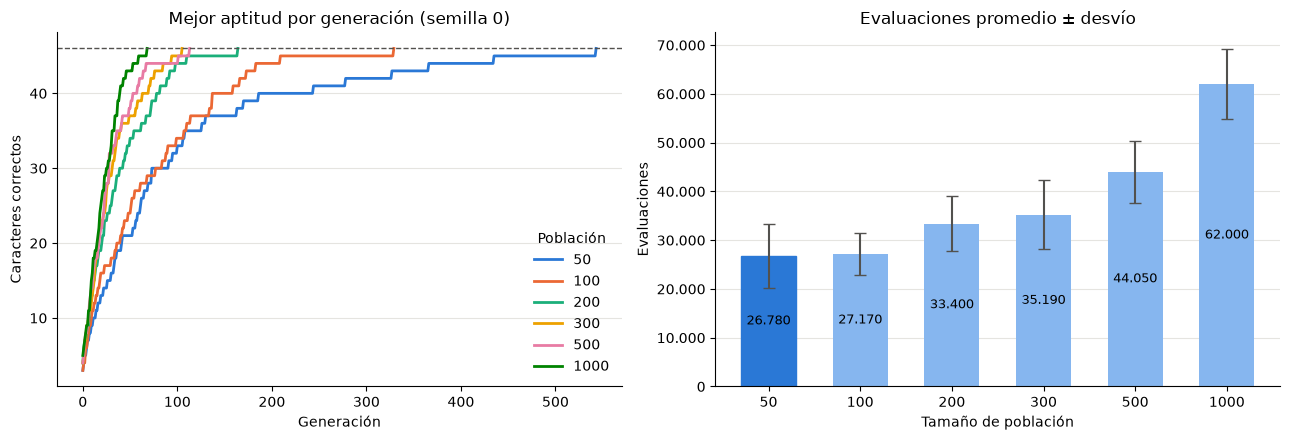

In [10]:
COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
orden = sorted(TAMANOS)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Izquierda: cómo sube la mejor aptitud generación a generación (semilla 0)
for tamano, color in zip(orden, COLORES):
    ax1.plot(resultados[tamano]["historial"], color=color, linewidth=2, label=f"{tamano}")
ax1.axhline(LARGO, color="#52514e", linewidth=1, linestyle="--")
ax1.set(title="Mejor aptitud por generación (semilla 0)", xlabel="Generación",
        ylabel="Caracteres correctos")
ax1.legend(title="Población", frameon=False)

# Derecha: trabajo total promedio de cada tamaño (las líneas negras marcan ± 1 desvío)
miles = lambda v, _=None: f"{v:,.0f}".replace(",", ".")
evals = [resultados[t]["evaluaciones"] for t in orden]
desvios = [resultados[t]["desvio"] for t in orden]
barras = ax2.bar([str(t) for t in orden], evals, yerr=desvios, capsize=4,
                 color="#86b6ef", ecolor="#52514e", width=0.6)
barras[orden.index(MEJOR_TAMANO)].set_color("#2a78d6")
ax2.bar_label(barras, labels=[miles(e) for e in evals], label_type="center", fontsize=9)
ax2.yaxis.set_major_formatter(miles)
ax2.set(title="Evaluaciones promedio ± desvío", xlabel="Tamaño de población",
        ylabel="Evaluaciones")

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### Conclusión
- **Mejor tamaño: 50.** Es el que encontró el texto con menos evaluaciones en promedio (≈ 26.800).
- **50 y 100 son prácticamente equivalentes.** La diferencia entre ambos (≈ 400 evaluaciones, 1,5 %) es mucho menor que la variación entre corridas (desvío de 4.000 a 6.500), así que no alcanza para afirmar que 50 sea mejor. 100 es algo más estable (menor desvío).
- **Desde 200 en adelante, cuanto más grande la población, más trabajo.** 1000 necesita la menor cantidad de generaciones (≈ 60), pero evalúa más del doble de individuos que 50.
- **En conclusión:** para este problema conviene una población chica (50–100). Una población grande converge en menos generaciones, pero a costa de evaluar muchos más individuos.

---
## Actividad 2: Optimizar funciones en el espacio

Se aproxima con AG un extremo de tres funciones: el mínimo de una función de ℜ² con selección por ruleta (2a), el máximo de otra función de ℜ² con un método de selección distinto (2b) y el máximo de una función de ℜ³ con restricciones (2c).

### 2a. Mínimo de f(x, y) = (x − 1)² + (x − y)⁴ con selección por ruleta

**Enunciado:** aproximar con un AG el mínimo de f(x, y) = (x − 1)² + (x − y)⁴ en ℜ², usando selección por rueda de ruleta.

**Solución analítica (para verificar):** los dos términos son ≥ 0 y se anulan en (1, 1), así que el mínimo es f(1, 1) = 0.

#### Planteo

| Elemento | Decisión |
|---|---|
| **Individuo** | 32 bits: los primeros 16 codifican x y los últimos 16 codifican y. |
| **Decodificación** | Bits → entero (0 a 65.535) → valor real: `v = −5 + 10 · entero / 65.535`. Precisión ≈ 0,00015. |
| **Rango** | x, y ∈ [−5, 5]. La consigna no acota el dominio, pero la codificación binaria necesita un intervalo finito. Se eligió uno que contiene al mínimo con margen (el gráfico de la consigna lo ubica cerca de (1, 1)) sin ser excesivo: con los mismos 16 bits, un rango más amplio pierde precisión y empeora la búsqueda (con [−50, 50], 6 de 10 corridas quedaron atrapadas lejos del mínimo). |
| **Función de aptitud** | 1 / (1 + f(x, y)). La selección favorece a los individuos de mayor aptitud, así que para buscar el **mínimo** de f la aptitud tiene que crecer cuando f baja: f = 0 da aptitud 1 (la máxima) y f grande da aptitud cercana a 0. Además es siempre positiva, como requiere la ruleta. El +1 evita dividir por cero en el mínimo. |
| **Selección** | Ruleta: cada individuo recibe una porción proporcional a su aptitud. |
| **Cruza** | En un punto sobre los 32 bits, con probabilidad 0,9. |
| **Mutación** | Cada bit se invierte (0 ↔ 1) con probabilidad 1/32. |
| **Elitismo** | El mejor individuo pasa sin cambios. |
| **Parada** | 200 generaciones con población de 100. Se corre 10 veces con semillas fijas. |

#### Implementación

##### 2a.1 Parámetros

In [11]:
BITS = 16                           # bits por variable
V_MIN, V_MAX = -5.0, 5.0            # rango de búsqueda de x e y
TAM_2A = 100                        # tamaño de población
GENERACIONES_2A = 200
PROB_CRUZA_2A = 0.9
PROB_MUTACION_2A = 1 / (2 * BITS)   # ≈ un bit por individuo

##### 2a.2 Población inicial y decodificación

In [12]:
def crear_individuo_bits(variables=2):
    """Lista de variables·BITS ceros y unos al azar: primero x, después y (y z en 2c)."""
    return [random.randint(0, 1) for _ in range(variables * BITS)]


def decodificar(bits, v_min=V_MIN, v_max=V_MAX):
    """Bits → entero (0 a 2^BITS − 1) → valor real en [v_min, v_max]."""
    entero = int("".join(map(str, bits)), 2)
    return v_min + (v_max - v_min) * entero / (2 ** BITS - 1)


def fenotipo(individuo):
    """Genotipo (bits) → fenotipo (x, y)."""
    return decodificar(individuo[:BITS]), decodificar(individuo[BITS:])

##### 2a.3 Función de aptitud

In [13]:
def f_2a(x, y):
    return (x - 1) ** 2 + (x - y) ** 4


def aptitud_2a(individuo):
    """1 / (1 + f): el mínimo de f pasa a ser la aptitud máxima (1), siempre positiva."""
    return 1 / (1 + f_2a(*fenotipo(individuo)))

##### 2a.4 Selección por ruleta

In [14]:
def seleccion_ruleta(poblacion, aptitudes):
    """Tira un número al azar entre 0 y la suma de aptitudes y recorre la población
    acumulando porciones hasta superarlo. Equivale a normalizar las porciones para
    que sumen 1, como en la consigna."""
    tiro = random.uniform(0, sum(aptitudes))
    acumulado = 0
    for individuo, apt in zip(poblacion, aptitudes):
        acumulado += apt
        if acumulado >= tiro:
            return individuo
    return poblacion[-1]   # solo por redondeo

##### 2a.5 Cruza en un punto
Igual que en la Actividad 1, pero sobre los 32 bits. Si el corte cae en los primeros 16, el hijo combina bits de x de ambos padres y toma la y de uno solo. Si cae en los últimos 16, toma la x de un padre y mezcla las y.

In [15]:
def cruza_bits(padre1, padre2):
    """Cruza en un punto sobre todos los bits, con probabilidad PROB_CRUZA_2A."""
    if random.random() < PROB_CRUZA_2A:
        punto = random.randint(1, len(padre1) - 1)
        return padre1[:punto] + padre2[punto:], padre2[:punto] + padre1[punto:]
    return padre1[:], padre2[:]

##### 2a.6 Mutación
Invertir un bit cambia el valor de x o de y: poco si es un bit de la derecha (salto chico) y mucho si es uno de la izquierda (salto grande). Así la mutación permite tanto ajustes finos como saltos a otras zonas.

In [16]:
def mutacion_bits(individuo, prob=PROB_MUTACION_2A):
    """Cada bit se invierte (0 ↔ 1) con probabilidad prob."""
    return [1 - bit if random.random() < prob else bit for bit in individuo]

##### 2a.7 Ciclo evolutivo

In [17]:
GENERACIONES_A_GRAFICAR = (0, 10, GENERACIONES_2A)


def ejecutar_ag_2a(semilla):
    """Corre GENERACIONES_2A generaciones y devuelve el mejor (x, y)."""
    random.seed(semilla)
    poblacion = [crear_individuo_bits() for _ in range(TAM_2A)]
    aptitudes = [aptitud_2a(ind) for ind in poblacion]
    instantaneas = {0: [fenotipo(ind) for ind in poblacion]}   # para el gráfico

    for generacion in range(1, GENERACIONES_2A + 1):
        # Elitismo: el mejor individuo pasa directo
        nueva = [poblacion[aptitudes.index(max(aptitudes))]]
        # Selección -> cruza -> mutación hasta completar la nueva población
        while len(nueva) < TAM_2A:
            padre1 = seleccion_ruleta(poblacion, aptitudes)
            padre2 = seleccion_ruleta(poblacion, aptitudes)
            for hijo in cruza_bits(padre1, padre2):
                nueva.append(mutacion_bits(hijo))
        # Reemplazo
        poblacion = nueva[:TAM_2A]
        aptitudes = [aptitud_2a(ind) for ind in poblacion]
        if generacion in GENERACIONES_A_GRAFICAR:
            instantaneas[generacion] = [fenotipo(ind) for ind in poblacion]

    x, y = fenotipo(poblacion[aptitudes.index(max(aptitudes))])
    return {"x": x, "y": y, "f": f_2a(x, y), "instantaneas": instantaneas}

#### Resultados

##### Corridas (10 semillas)

In [18]:
corridas_2a = [ejecutar_ag_2a(semilla) for semilla in range(10)]

print(f"{'Semilla':>7} | {'x':>7} | {'y':>7} | {'f(x, y)':>9}")
for semilla, c in enumerate(corridas_2a):
    print(f"{semilla:>7} | {c['x']:>7.4f} | {c['y']:>7.4f} | {c['f']:>9.1e}")
print(f"\nError promedio: |x − 1| = {statistics.mean(abs(c['x'] - 1) for c in corridas_2a):.4f}"
      f"   |y − 1| = {statistics.mean(abs(c['y'] - 1) for c in corridas_2a):.4f}")

Semilla |       x |       y |   f(x, y)
      0 |  1.0000 |  1.0000 |   0.0e+00
      1 |  1.0000 |  1.0000 |   0.0e+00
      2 |  1.0000 |  0.9998 |   5.4e-16
      3 |  1.0000 |  1.0038 |   2.1e-10
      4 |  1.0000 |  0.9985 |   5.4e-12
      5 |  1.0000 |  1.0000 |   0.0e+00
      6 |  1.0002 |  1.0002 |   2.3e-08
      7 |  1.0000 |  1.0002 |   5.4e-16
      8 |  1.0000 |  1.0111 |   1.5e-08
      9 |  1.0000 |  1.0000 |   0.0e+00

Error promedio: |x − 1| = 0.0000   |y − 1| = 0.0017


##### Gráfico

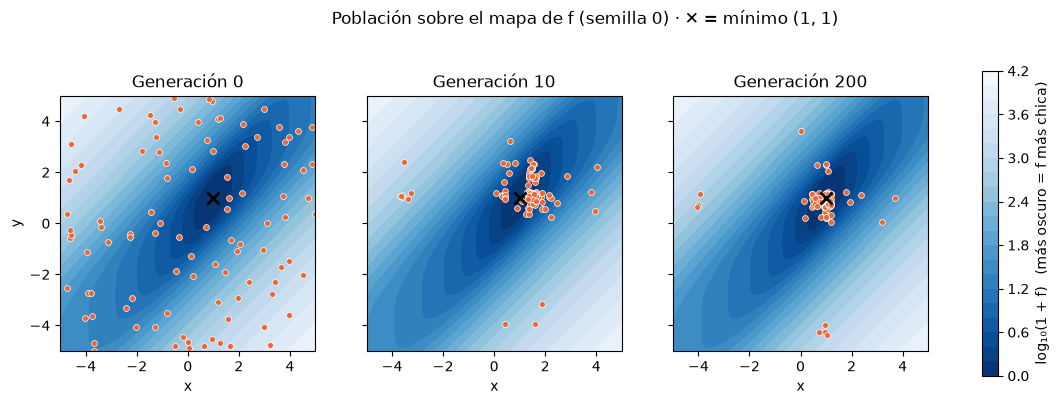

In [19]:
malla = np.linspace(V_MIN, V_MAX, 300)
X, Y = np.meshgrid(malla, malla)
Z = np.log10(1 + f_2a(X, Y))     # escala logarítmica: f va de 0 a ~10.000

fig, ejes = plt.subplots(1, 3, figsize=(14, 4.4), sharey=True)
for ax, gen in zip(ejes, GENERACIONES_A_GRAFICAR):
    fondo = ax.contourf(X, Y, Z, levels=20, cmap="Blues_r")
    xs, ys = zip(*corridas_2a[0]["instantaneas"][gen])
    ax.scatter(xs, ys, s=18, color="#eb6834", edgecolor="white", linewidth=0.5)
    ax.plot(1, 1, marker="x", color="black", markersize=9, mew=2)
    ax.set(title=f"Generación {gen}", xlabel="x", aspect="equal")
ejes[0].set_ylabel("y")
fig.colorbar(fondo, ax=ejes, label="log₁₀(1 + f)   (más oscuro = f más chica)", shrink=0.9)
fig.suptitle("Población sobre el mapa de f (semilla 0) · ✕ = mínimo (1, 1)")
plt.show()

#### Conclusión
- **El AG encontró el mínimo en las 10 corridas.** x vale 1,0000 en 9 de 10 corridas (1,0002 en la otra), la variable y se aleja de 1 en 0,0017 en promedio, y f(x, y) ≤ 2·10⁻⁸ en todas.
- **x se aproxima mejor que y.** Cerca del mínimo, el término (x − y)⁴ es casi plano: pequeños errores en y prácticamente no cambian f ni la aptitud, así que la ruleta no distingue esos individuos y no presiona para afinar y.
- **El gráfico muestra la convergencia.** En la generación 0 la población está dispersa en todo el rango; en la 10 ya se concentra alrededor de (1, 1). Algunos puntos alejados persisten por la mutación, que mantiene la diversidad.

### 2b. Máximo de f(x, y) = 2 + √(9 − x² − y²) con selección por torneo

**Enunciado:** proponer un método diferente al del ejercicio anterior y aproximar con un AG el máximo de f(x, y) = 2 + √(9 − x² − y²) en la zona donde es real, es decir, donde 9 − x² − y² ≥ 0.

**Solución analítica (para verificar):** la raíz es máxima cuando x² + y² es mínimo, o sea en (0, 0): f(0, 0) = 2 + √9 = 5.

#### Planteo

**Método propuesto:** se cambia solo la selección, **torneo** en lugar de ruleta. La representación, la cruza y la mutación son las de 2a, así la única diferencia entre ambos ejercicios es el método de selección.

| Elemento | Decisión |
|---|---|
| **Individuo** | 32 bits (16 por variable), como en 2a. |
| **Rango** | x, y ∈ [−3, 3]: el menor cuadrado que contiene al círculo x² + y² ≤ 9, donde f es real. |
| **Restricción** | Los puntos del cuadrado que quedan fuera del círculo (las esquinas) no tienen f real y reciben aptitud 0. Como dentro del círculo f ≥ 2, siempre pierden el torneo. |
| **Función de aptitud** | f(x, y) dentro del círculo y 0 fuera. Se busca un máximo y f es positiva, así que no hace falta transformarla (a diferencia de 2a). |
| **Selección** | Torneo con k = 3: se eligen 3 individuos al azar y gana el de mayor aptitud. Solo importa *quién* es mejor, no *por cuánto*, así que sigue eligiendo al mejor aunque las aptitudes sean muy parecidas. A la ruleta, en cambio, eso le quita presión de selección (es lo que en 2a frenó el ajuste de y). |
| **Cruza y mutación** | Las de 2a: un punto (probabilidad 0,9) e inversión de bits (probabilidad 1/32). |
| **Elitismo** | El mejor individuo pasa sin cambios. |
| **Parada** | 100 generaciones con población de 100. Se corre 10 veces con semillas fijas, con torneo y, para comparar, con ruleta. |

#### Implementación

##### 2b.1 Parámetros

In [20]:
R_2B = 3.0               # rango de búsqueda: [−3, 3]
TAM_2B = 100
GENERACIONES_2B = 100

##### 2b.2 Población inicial y decodificación
La población se crea con `crear_individuo_bits` de 2a. Solo cambia el rango de la decodificación.

In [21]:
def fenotipo_2b(individuo):
    """Genotipo (bits) → fenotipo (x, y) en [−3, 3]."""
    return (decodificar(individuo[:BITS], -R_2B, R_2B),
            decodificar(individuo[BITS:], -R_2B, R_2B))

##### 2b.3 Función de aptitud

In [22]:
def f_2b(x, y):
    return 2 + (9 - x**2 - y**2) ** 0.5


def aptitud_2b(individuo):
    """f(x, y) dentro del círculo x² + y² ≤ 9; fuera, f no es real y se penaliza con 0."""
    x, y = fenotipo_2b(individuo)
    if x**2 + y**2 > 9:
        return 0
    return f_2b(x, y)

##### 2b.4 Selección por torneo
Se usa `seleccion_torneo` de la Actividad 1 (k = 3). Solo mira las aptitudes, así que sirve igual para cadenas de texto que para bits.

##### 2b.5 Cruza y mutación
Se usan `cruza_bits` y `mutacion_bits` de 2a.

##### 2b.6 Ciclo evolutivo

In [23]:
GENERACIONES_A_GRAFICAR_2B = (0, 5, GENERACIONES_2B)


def ejecutar_ag_2b(semilla, seleccion):
    """Corre el AG con el método de selección indicado y devuelve el mejor (x, y)."""
    random.seed(semilla)
    poblacion = [crear_individuo_bits() for _ in range(TAM_2B)]
    aptitudes = [aptitud_2b(ind) for ind in poblacion]
    instantaneas = {0: [fenotipo_2b(ind) for ind in poblacion]}   # para el gráfico

    for generacion in range(1, GENERACIONES_2B + 1):
        # Elitismo: el mejor individuo pasa directo
        nueva = [poblacion[aptitudes.index(max(aptitudes))]]
        # Selección -> cruza -> mutación hasta completar la nueva población
        while len(nueva) < TAM_2B:
            padre1 = seleccion(poblacion, aptitudes)
            padre2 = seleccion(poblacion, aptitudes)
            for hijo in cruza_bits(padre1, padre2):
                nueva.append(mutacion_bits(hijo))
        # Reemplazo
        poblacion = nueva[:TAM_2B]
        aptitudes = [aptitud_2b(ind) for ind in poblacion]
        if generacion in GENERACIONES_A_GRAFICAR_2B:
            instantaneas[generacion] = [fenotipo_2b(ind) for ind in poblacion]

    x, y = fenotipo_2b(poblacion[aptitudes.index(max(aptitudes))])
    return {"x": x, "y": y, "f": f_2b(x, y), "instantaneas": instantaneas}

#### Resultados

##### Torneo contra ruleta (10 semillas)

In [24]:
corridas_2b = {
    "Torneo": [ejecutar_ag_2b(semilla, seleccion_torneo) for semilla in range(10)],
    "Ruleta": [ejecutar_ag_2b(semilla, seleccion_ruleta) for semilla in range(10)],
}

# Distancia del mejor punto encontrado al máximo (0, 0)
print(f"{'Selección':>9} | {'Distancia media a (0,0)':>23} | {'Peor distancia':>14} | {'f media':>8}")
for metodo, corridas in corridas_2b.items():
    distancias = [(c["x"]**2 + c["y"]**2) ** 0.5 for c in corridas]
    print(f"{metodo:>9} | {statistics.mean(distancias):>23.5f} | {max(distancias):>14.5f} | "
          f"{statistics.mean(c['f'] for c in corridas):>8.5f}")

Selección | Distancia media a (0,0) | Peor distancia |  f media
   Torneo |                 0.00006 |        0.00006 |  5.00000
   Ruleta |                 0.00267 |        0.00605 |  5.00000


##### Gráfico (torneo)

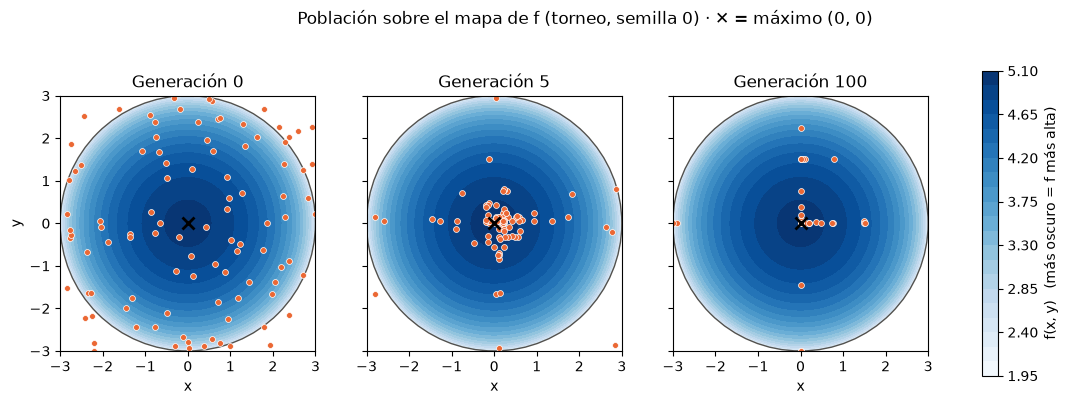

In [25]:
malla = np.linspace(-R_2B, R_2B, 300)
X, Y = np.meshgrid(malla, malla)
dentro = X**2 + Y**2 <= 9
Z = np.where(dentro, 2 + np.sqrt(np.where(dentro, 9 - X**2 - Y**2, 0)), np.nan)   # fuera del círculo: sin color

fig, ejes = plt.subplots(1, 3, figsize=(14, 4.4), sharey=True)
for ax, gen in zip(ejes, GENERACIONES_A_GRAFICAR_2B):
    fondo = ax.contourf(X, Y, Z, levels=20, cmap="Blues")
    ax.add_patch(plt.Circle((0, 0), 3, fill=False, color="#52514e", linewidth=1))
    xs, ys = zip(*corridas_2b["Torneo"][0]["instantaneas"][gen])
    ax.scatter(xs, ys, s=18, color="#eb6834", edgecolor="white", linewidth=0.5)
    ax.plot(0, 0, marker="x", color="black", markersize=9, mew=2)
    ax.set(title=f"Generación {gen}", xlabel="x", aspect="equal",
           xlim=(-R_2B, R_2B), ylim=(-R_2B, R_2B))
ejes[0].set_ylabel("y")
fig.colorbar(fondo, ax=ejes, label="f(x, y)   (más oscuro = f más alta)", shrink=0.9)
fig.suptitle("Población sobre el mapa de f (torneo, semilla 0) · ✕ = máximo (0, 0)")
plt.show()

#### Conclusión
- **Los dos métodos llegan al máximo (f ≈ 5), pero el torneo es mucho más preciso.** Con torneo, el mejor punto queda a 0,00006 de (0, 0) en todas las corridas, que es el punto más cercano a (0, 0) que permiten los 16 bits. Con ruleta queda a 0,0027 en promedio, unas 45 veces más lejos.
- **Por qué:** cerca del máximo la cúpula es casi plana y todas las aptitudes valen ≈ 5, así que la ruleta reparte porciones casi iguales y elige prácticamente al azar. El torneo solo compara quién es mejor, así que sigue favoreciendo al más cercano a (0, 0) aunque la diferencia sea mínima.
- **Converge rápido:** en la generación 5 la población ya se concentra alrededor del máximo. Los puntos alineados con los ejes son mutaciones que cambiaron solo x o solo y.

### 2c. Máximo de f(x, y, z) = z − x² − 15y² con −2 < x, y, z < 11

**Enunciado:** buscar la mejor solución para el máximo de f(x, y, z) = z − x² − 15y² en ℜ³, con la restricción −2 < x, y, z < 11.

**Solución analítica (para verificar):** z suma, mientras que x² y 15y² restan, así que conviene x = y = 0 y z lo más grande posible. Como z < 11 es estricto, f no alcanza un máximo: se acerca a 11 sin llegar nunca. El AG solo puede aproximarlo, y con 16 bits el valor más cercano a 11 que puede tomar z es 10,9998.

#### Planteo

| Elemento | Decisión |
|---|---|
| **Individuo** | 48 bits: 16 para x, 16 para y y 16 para z. |
| **Restricción** | La desigualdad es estricta, así que la decodificación usa solo las marcas interiores del intervalo: `v = −2 + 13 · (entero + 1) / 65.537`. Va de −1,9998 a 10,9998 y nunca da exactamente −2 ni 11. Así todo individuo cumple la restricción por construcción y no hace falta penalizar (a diferencia de 2b). |
| **Función de aptitud** | f(x, y, z) directamente, porque se busca un máximo. Puede ser negativa (hasta ≈ −1.938), pero eso no afecta al torneo, que solo compara quién es mejor. La ruleta, en cambio, necesitaría aptitudes positivas. |
| **Selección** | Torneo con k = 3. La consigna deja el método libre, y en 2b el torneo fue más preciso que la ruleta. |
| **Cruza y mutación** | Las de 2a sobre los 48 bits: un punto (probabilidad 0,9) e inversión de bits (probabilidad 1/48). |
| **Elitismo** | El mejor individuo pasa sin cambios. |
| **Población** | 200. Se probaron 100, 120, 150, 200 y 300 (10 corridas cada uno). Por debajo de 200, algunas corridas quedaron atrapadas con x o y lejos de 0; 200 es el menor tamaño que llegó al óptimo en las 10 corridas. |
| **Parada** | 200 generaciones. Se corre 10 veces con semillas fijas. |

#### Implementación

##### 2c.1 Parámetros

In [26]:
A_2C, B_2C = -2.0, 11.0     # restricción: A_2C < x, y, z < B_2C
TAM_2C = 200
GENERACIONES_2C = 200
PROB_MUTACION_2C = 1 / (3 * BITS)   # ≈ un bit por individuo

##### 2c.2 Población inicial y decodificación
La población se crea con `crear_individuo_bits(variables=3)`. La decodificación cambia para respetar la desigualdad estricta.

In [27]:
def decodificar_2c(bits):
    """Como decodificar, pero solo con las marcas interiores del intervalo:
    nunca da exactamente A_2C ni B_2C."""
    entero = int("".join(map(str, bits)), 2)
    return A_2C + (B_2C - A_2C) * (entero + 1) / (2 ** BITS + 1)


def fenotipo_2c(individuo):
    """Genotipo (48 bits) → fenotipo (x, y, z)."""
    return tuple(decodificar_2c(individuo[i * BITS:(i + 1) * BITS]) for i in range(3))

##### 2c.3 Función de aptitud

In [28]:
def f_2c(x, y, z):
    return z - x**2 - 15 * y**2


def aptitud_2c(individuo):
    """f(x, y, z) directamente: se maximiza y el torneo admite valores negativos."""
    return f_2c(*fenotipo_2c(individuo))

##### 2c.4 Selección por torneo
Se usa `seleccion_torneo` de la Actividad 1 (k = 3).

##### 2c.5 Cruza y mutación
Se usan `cruza_bits` y `mutacion_bits` de 2a, con probabilidad de mutación 1/48.

##### 2c.6 Ciclo evolutivo

In [29]:
def ejecutar_ag_2c(semilla, tamano=TAM_2C):
    """Corre el AG y devuelve el mejor (x, y, z) y su evolución por generación."""
    random.seed(semilla)
    poblacion = [crear_individuo_bits(variables=3) for _ in range(tamano)]
    aptitudes = [aptitud_2c(ind) for ind in poblacion]
    historial = [fenotipo_2c(poblacion[aptitudes.index(max(aptitudes))])]   # mejor (x, y, z)

    for generacion in range(1, GENERACIONES_2C + 1):
        # Elitismo: el mejor individuo pasa directo
        nueva = [poblacion[aptitudes.index(max(aptitudes))]]
        # Selección -> cruza -> mutación hasta completar la nueva población
        while len(nueva) < tamano:
            padre1 = seleccion_torneo(poblacion, aptitudes)
            padre2 = seleccion_torneo(poblacion, aptitudes)
            for hijo in cruza_bits(padre1, padre2):
                nueva.append(mutacion_bits(hijo, PROB_MUTACION_2C))
        # Reemplazo
        poblacion = nueva[:tamano]
        aptitudes = [aptitud_2c(ind) for ind in poblacion]
        historial.append(fenotipo_2c(poblacion[aptitudes.index(max(aptitudes))]))

    x, y, z = historial[-1]
    return {"x": x, "y": y, "z": z, "f": f_2c(x, y, z), "historial": historial}

#### Resultados

##### Corridas (10 semillas)

In [30]:
corridas_2c = [ejecutar_ag_2c(semilla) for semilla in range(10)]

print(f"{'Semilla':>7} | {'x':>8} | {'y':>8} | {'z':>8} | {'f(x, y, z)':>10}")
for semilla, c in enumerate(corridas_2c):
    print(f"{semilla:>7} | {c['x']:>8.5f} | {c['y']:>8.5f} | {c['z']:>8.5f} | {c['f']:>10.5f}")

Semilla |        x |        y |        z | f(x, y, z)
      0 |  0.00008 |  0.00008 | 10.99980 |   10.99980
      1 |  0.00008 |  0.00008 | 10.99980 |   10.99980
      2 |  0.00008 |  0.00008 | 10.99980 |   10.99980
      3 |  0.00008 |  0.00008 | 10.99980 |   10.99980
      4 |  0.00008 |  0.00008 | 10.99980 |   10.99980
      5 |  0.00008 |  0.00008 | 10.99980 |   10.99980
      6 |  0.00008 |  0.00008 | 10.99980 |   10.99980
      7 |  0.00008 |  0.00008 | 10.99980 |   10.99980
      8 |  0.00008 |  0.00008 | 10.99980 |   10.99980
      9 |  0.00008 |  0.00008 | 10.99980 |   10.99980


##### Gráfico

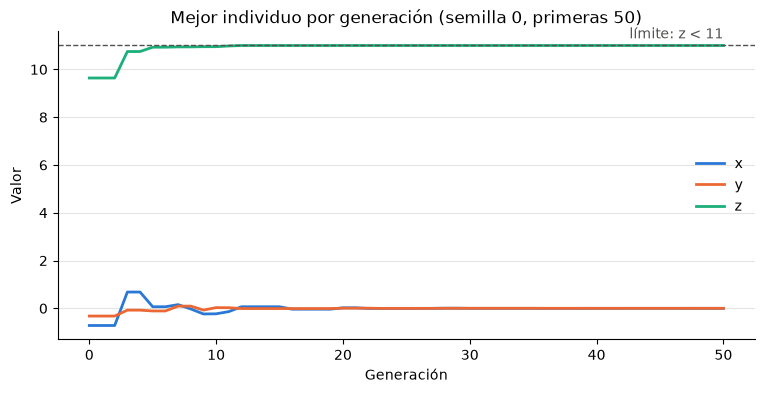

In [31]:
historial = corridas_2c[0]["historial"][:51]   # después de la generación 50 no cambia
fig, ax = plt.subplots(figsize=(9, 4))
for indice, (nombre, color) in enumerate([("x", "#2a78d6"), ("y", "#eb6834"), ("z", "#1baf7a")]):
    ax.plot([punto[indice] for punto in historial], color=color, linewidth=2, label=nombre)
ax.axhline(11, color="#52514e", linewidth=1, linestyle="--")
ax.text(50, 11.3, "límite: z < 11", ha="right", color="#52514e")
ax.set(title="Mejor individuo por generación (semilla 0, primeras 50)", xlabel="Generación", ylabel="Valor")
ax.legend(frameon=False, loc="center right")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
plt.show()

#### Conclusión
- **Las 10 corridas llegan a la misma solución:** x = y = 0,00008 y z = 10,9998, con f = 10,9998. Son los valores más cercanos al óptimo que se pueden representar con 16 bits: el 0 no cae exactamente en una marca de la regla y z no puede valer 11.
- **La restricción se cumple siempre, por construcción:** z se acerca a 11 tanto como lo permite la precisión, sin alcanzarlo. Con más bits se acercaría más, pero nunca llegaría a 11, porque f no tiene un máximo, solo un valor al que se aproxima.
- **Converge rápido:** en unas 20 generaciones el mejor individuo ya está en la solución. z sube primero porque suma directamente a f, y x e y terminan de ajustarse a 0 en las generaciones siguientes.

---
## Actividad 3: Selección de variables con AG

**Enunciado:** estudiar el [artículo de Zachary Warnes](https://towardsdatascience.com/feature-selection-with-genetic-algorithms-7dd7e02dd237) y aplicar el algoritmo genético para seleccionar las mejores variables (*features*) del dataset [Wine](https://archive.ics.uci.edu/ml/datasets/wine). Probar con distintos números de generaciones, reportar los resultados e identificar en el algoritmo las etapas Seleccionar, Cruzar, Mutar y Reemplazar.

### Planteo

**Datos:** Wine tiene 178 vinos, 13 variables químicas (alcohol, magnesio, prolina, etc.) y 3 clases (el cultivar de origen). Es el mismo dataset que trae `sklearn.datasets.load_wine`.

**Algoritmo:** el del artículo, `GeneticSelectionCV` de la librería `sklearn-genetic`. Requiere scikit-learn 1.5.2: con versiones posteriores falla, porque usa funciones internas de scikit-learn que fueron eliminadas.

| Elemento | Decisión |
|---|---|
| **Individuo** | Máscara de 13 bits: 1 = la variable se usa, 0 = se descarta. |
| **Función de aptitud** | Accuracy promedio de un clasificador entrenado solo con las variables activas, medido con validación cruzada de 5 partes: se entrena con 4/5 de los vinos y se mide con el 1/5 restante, rotando. Si dos máscaras empatan, gana la que usa menos variables. |
| **Clasificador** | KNN (5 vecinos, variables estandarizadas): clasifica cada vino según los vinos conocidos más parecidos. Las variables que no aportan lo confunden, así que se beneficia de elegir bien. |
| **Parámetros** | Los de la librería por defecto: población 300, torneo k = 3, cruza 0,5, mutación 0,2. Se varían las generaciones (1, 5, 10, 20 y 40), con 5 corridas para cada valor. |
| **Verificación** | Con 13 variables hay 2¹³ − 1 = 8.191 subconjuntos posibles, así que se pueden evaluar todos (búsqueda exhaustiva) para saber cuál es realmente el mejor y comparar al AG con ese óptimo. |

### Etapas del algoritmo en `GeneticSelectionCV`

Fragmentos del código de la librería (`genetic_selection/gscv.py`):

```python
# Configuración de los operadores (método _fit)
toolbox.register("mate", tools.cxUniform, indpb=self.crossover_independent_proba)
toolbox.register("mutate", tools.mutFlipBit, indpb=self.mutation_independent_proba)
toolbox.register("select", tools.selTournament, tournsize=self.tournament_size)

# Ciclo evolutivo (función _eaFunction), en cada generación
offspring = toolbox.select(population, len(population) - hof_size)
offspring = algorithms.varAnd(offspring, toolbox, cxpb, mutpb)
...
offspring.extend(halloffame.items)
halloffame.update(offspring)
population[:] = offspring
```

| Etapa | Dónde ocurre | Qué hace |
|---|---|---|
| **Seleccionar** | `selTournament` | Elige los padres por torneo de 3: toma 3 máscaras al azar y gana la de mayor aptitud. |
| **Cruzar** | `cxUniform`, dentro de `varAnd` | Cada pareja se cruza con probabilidad 0,5. La cruza es **uniforme**: en vez de cortar en un punto, cada gen se intercambia entre los padres con probabilidad 0,1. |
| **Mutar** | `mutFlipBit`, dentro de `varAnd` | Cada hijo muta con probabilidad 0,2: cada bit se invierte con probabilidad 0,05, lo que prende o apaga una variable. |
| **Reemplazar** | `offspring.extend(halloffame.items)` y `population[:] = offspring` | Los hijos reemplazan a toda la población, junto con el mejor individuo encontrado hasta el momento (*hall of fame*, es decir, elitismo). |

La aptitud se calcula en `_evalFunction`, que entrena el clasificador con las columnas activas usando `cross_val_score`.

### Implementación

#### 3.1 Datos y clasificador

In [32]:
import itertools

from genetic_selection import GeneticSelectionCV
from sklearn.datasets import load_wine
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

vinos = load_wine()
X_vino, y_vino = vinos.data, vinos.target
NOMBRES = vinos.feature_names

# Clasificador con el que se mide la aptitud: KNN sobre variables estandarizadas
clasificador = make_pipeline(StandardScaler(), KNeighborsClassifier())
validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)   # siempre las mismas 5 partes


def accuracy_con(mascara):
    """Aptitud de una máscara: accuracy promedio de validación cruzada usando esas variables."""
    return cross_val_score(clasificador, X_vino[:, mascara], y_vino, cv=validacion).mean()


TODAS = np.ones(13, dtype=bool)
print(f"Accuracy con las 13 variables: {accuracy_con(TODAS):.4f}")

Accuracy con las 13 variables: 0.9608


#### 3.2 Búsqueda exhaustiva (referencia)
Evalúa las 8.191 máscaras posibles y se queda con la de mayor accuracy (a igual accuracy, la de menos variables). Tarda unos 3 minutos.

In [33]:
inicio = time.time()
mascaras = (np.array(m) for m in itertools.product([False, True], repeat=13) if any(m))
MEJOR_MASCARA = max(mascaras, key=lambda m: (accuracy_con(m), -m.sum()))
ACC_OPTIMA = accuracy_con(MEJOR_MASCARA)

print(f"Óptimo: {ACC_OPTIMA:.4f} con {MEJOR_MASCARA.sum()} variables ({time.time() - inicio:.0f} s)")
print([NOMBRES[i] for i in np.flatnonzero(MEJOR_MASCARA)])

Óptimo: 0.9944 con 6 variables (107 s)
['alcohol', 'alcalinity_of_ash', 'magnesium', 'flavanoids', 'color_intensity', 'proline']


#### 3.3 Algoritmo genético
Solo se fija el clasificador, la validación y la cantidad de generaciones. El resto son los valores por defecto de la librería.

In [34]:
def ejecutar_ag_3(generaciones, semilla):
    """Corre GeneticSelectionCV con la cantidad de generaciones indicada."""
    random.seed(semilla)       # azar de los operadores (DEAP)
    np.random.seed(semilla)    # azar de la población inicial
    selector = GeneticSelectionCV(
        clasificador,
        cv=validacion,
        scoring="accuracy",
        n_generations=generaciones,
        caching=True,              # no vuelve a evaluar máscaras repetidas
    )
    selector.fit(X_vino, y_vino)
    return selector

### Resultados

#### Distintas cantidades de generaciones (5 corridas cada una)

In [35]:
GENERACIONES_3 = [1, 5, 10, 20, 40]
CORRIDAS_3 = 5

resultados_3 = {}
for generaciones in GENERACIONES_3:
    inicio = time.time()
    selectores = [ejecutar_ag_3(generaciones, semilla) for semilla in range(CORRIDAS_3)]
    resultados_3[generaciones] = {
        "selectores": selectores,
        "accuracy": [accuracy_con(s.support_) for s in selectores],
        "variables": [int(s.n_features_) for s in selectores],
        "tiempo": (time.time() - inicio) / CORRIDAS_3,
    }

print(f"Referencias: 13 variables → {accuracy_con(TODAS):.4f}   |   "
      f"óptimo ({MEJOR_MASCARA.sum()} variables) → {ACC_OPTIMA:.4f}\n")
print(f"{'Generaciones':>12} | {'Accuracy media':>14} | {'Variables (media)':>17} | "
      f"{'Llegaron al óptimo':>18} | {'Tiempo (s)':>10}")
for generaciones, r in resultados_3.items():
    llegaron = sum(a >= ACC_OPTIMA - 1e-9 for a in r["accuracy"])
    print(f"{generaciones:>12} | {statistics.mean(r['accuracy']):>14.4f} | "
          f"{statistics.mean(r['variables']):>17.1f} | {llegaron:>13} de {CORRIDAS_3} | {r['tiempo']:>10.1f}")

# Variables elegidas por la mejor corrida de 40 generaciones
mejor = max(resultados_3[40]["selectores"], key=lambda s: (accuracy_con(s.support_), -s.n_features_))
print(f"\nMejor corrida con 40 generaciones ({mejor.n_features_} variables):")
print([NOMBRES[i] for i in np.flatnonzero(mejor.support_)])

Referencias: 13 variables → 0.9608   |   óptimo (6 variables) → 0.9944

Generaciones | Accuracy media | Variables (media) | Llegaron al óptimo | Tiempo (s)
           1 |         0.9831 |               8.2 |             0 de 5 |        4.2
           5 |         0.9877 |               6.4 |             1 de 5 |        6.5
          10 |         0.9911 |               6.8 |             3 de 5 |        7.6
          20 |         0.9933 |               6.4 |             4 de 5 |        8.5
          40 |         0.9933 |               6.4 |             4 de 5 |        9.2

Mejor corrida con 40 generaciones (6 variables):
['alcohol', 'alcalinity_of_ash', 'magnesium', 'flavanoids', 'color_intensity', 'proline']


#### Gráfico

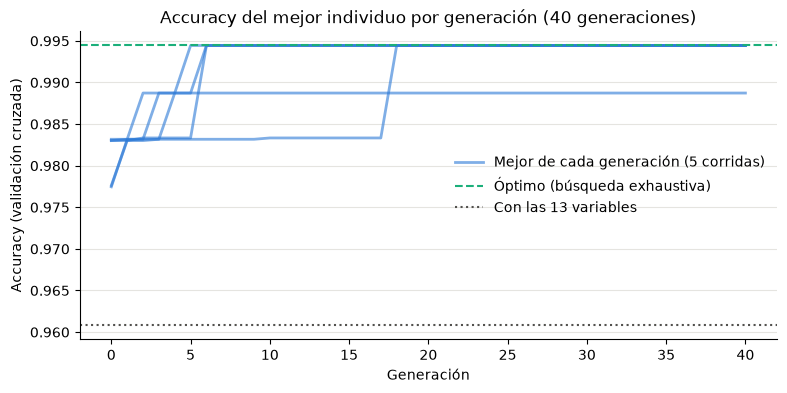

In [36]:
fig, ax = plt.subplots(figsize=(9, 4))
for semilla, selector in enumerate(resultados_3[40]["selectores"]):
    ax.plot(selector.generation_scores_, color="#2a78d6", linewidth=2, alpha=0.6,
            label="Mejor de cada generación (5 corridas)" if semilla == 0 else None)
ax.axhline(ACC_OPTIMA, color="#1baf7a", linewidth=1.5, linestyle="--", label="Óptimo (búsqueda exhaustiva)")
ax.axhline(accuracy_con(TODAS), color="#52514e", linewidth=1.5, linestyle=":", label="Con las 13 variables")
ax.set(title="Accuracy del mejor individuo por generación (40 generaciones)",
       xlabel="Generación", ylabel="Accuracy (validación cruzada)")
ax.legend(frameon=False, loc="center right")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
plt.show()

### Conclusión
- **Con menos variables, el clasificador acierta más.** Con las 13 variables, KNN acierta el 96,1 %. La mejor selección del AG usa 6 variables (alcohol, alcalinidad de la ceniza, magnesio, flavonoides, intensidad de color y prolina) y llega al 99,4 %, que es el óptimo según la búsqueda exhaustiva. Las variables descartadas no aportaban y confundían al clasificador.
- **Más generaciones mejoran el resultado, hasta cierto punto.** Con 1 generación ninguna corrida llega al óptimo; con 10 llegan 3 de 5, y con 20, 4 de 5. Entre 20 y 40 no hay cambios: la corrida restante quedó en 98,9 % con otro subconjunto y no salió de ahí.
- **Una de las corridas que llega a 99,4 % usa 7 variables.** Hay otro subconjunto con el mismo accuracy; el criterio de desempate prefiere el de 6, pero esa corrida no lo encontró.
- **El AG es más rápido que probar todo.** Con 13 variables todavía se pueden evaluar las 8.191 combinaciones, pero el AG tarda unas 10 veces menos. Con 30 variables (como el dataset del artículo) serían más de mil millones de combinaciones, y la búsqueda exhaustiva dejaría de ser viable.